# Crime Prediction - Model to predict the location of next crime

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data exploratory

In [46]:
cluster = pd.read_csv("cluster_location.csv")

crime = pd.read_csv('crime.csv', header=0)
print(crime.head())

        City  crimeCluster  Murder  Assault  CaseResolved  Kidnapping
0     Ottawa             4    13.2      236            58        21.2
1    Toronto             4    10.0      263            48        44.5
2   Montreal             4     8.1      294            80        31.0
3     Quebec             3     8.8      190            50        19.5
4  Vancouver             4     9.0      276            91        40.6


In [22]:
def stateToNumber(s):
    l = 0
    for x in s:
        l = l + int(hex(ord(x)),16)
    return l

xref = pd.DataFrame(crime['City'])
crime['City']=crime['City'].apply(lambda x: stateToNumber(x))
crime.head()

,City,crimeCluster,Murder,Assault,CaseResolved,Kidnapping
0,624,4,13.2,236,58,21.2
1,757,4,10.0,263,48,44.5
2,834,4,8.1,294,80,31.0
3,597,3,8.8,190,50,19.5
4,953,4,9.0,276,91,40.6


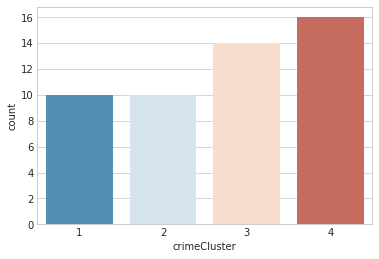

In [23]:
%matplotlib inline

sns.set_style('whitegrid')
sns.countplot(x='crimeCluster',data=crime,palette='RdBu_r')

## 2. Model Training

In [24]:
from sagemaker import KMeans
from sagemaker import get_execution_role

role = get_execution_role()
print(role)

bucket = "alexbc.datalake"

data_location = 's3://{}/kidnapping-records/model/data'.format(bucket)
output_location = 's3://{}/kidnapping-records/model/output'.format(bucket)

print('training data will be uploaded to: {}'.format(data_location))
print('training artifacts will be uploaded to: {}'.format(output_location))

kmeans = KMeans(role=role,
                train_instance_count=1,
                train_instance_type='ml.m4.xlarge',
                output_path=output_location,
                k=10,
                data_location=data_location)

arn:aws:iam::771620814942:role/service-role/AmazonSageMaker-ExecutionRole-20171212T090635
training data will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/data
training artifacts will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/output


In [25]:
crimeArray = crime.as_matrix().astype(np.float32)
crimeArray.shape
slice=crimeArray[:,1:5]

In [26]:
%%time
kmeans.fit(kmeans.record_set(slice))

INFO:sagemaker:Creating training-job with name: kmeans-2018-10-26-15-36-36-210


2018-10-26 15:36:36 Starting - Starting the training job...
2018-10-26 15:36:38 Starting - Launching requested ML instances......
2018-10-26 15:37:43 Starting - Preparing the instances for training......
2018-10-26 15:39:04 Downloading - Downloading input data...
2018-10-26 15:39:34 Training - Downloading the training image.
Docker entrypoint called with argument(s): train
[10/26/2018 15:39:39 INFO 140060671149888] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/resources/default-input.json: {u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'local_lloyd_num_trials': u'auto', u'_log_level': u'info', u'_kvstore': u'auto', u'local_lloyd_init_method': u'kmeans++', u'force_dense': u'true', u'epochs': u'1', u'init_method': u'random', u'local_lloyd_tol': u'0.0001', u'local_lloyd_max_iter': u'300', u'_disable_wait_to_read': u'false', u'extra_center_factor': u'auto', u'eval_metrics': u'["msd"]', u'_num_kv_servers': u'1', u'mini_batch_size': u'5000',


2018-10-26 15:39:49 Uploading - Uploading generated training model
2018-10-26 15:39:49 Completed - Training job completed
Billable seconds: 45
CPU times: user 451 ms, sys: 45.4 ms, total: 496 ms
Wall time: 3min 42s


## 3. Model Deployment - Moving the model to the production

In [ ]:
%%time
kmeans_predictor = kmeans.deploy(initial_instance_count=1,
                                 instance_type='ml.m4.xlarge')

INFO:sagemaker:Creating model with name: kmeans-2018-10-26-15-42-09-182
INFO:sagemaker:Creating endpoint with name kmeans-2018-10-26-15-36-36-210


--------------------------------------------------------

## 4. Inference

In [28]:
!pip install git+https://github.com/psychemedia/ipython_magic_folium.git
%load_ext folium_magic

  Cloning https://github.com/psychemedia/ipython_magic_folium.git to /tmp/pip-req-build-EIluIL
  Running setup.py bdist_wheel for ipython-magic-folium ... done
  Stored in directory: /tmp/pip-ephem-wheel-cache-iAD2bx/wheels/7c/49/f8/8577b6d1b8fcaa766dd7c6f7996f22a913e4a260443e75a095
Successfully built ipython-magic-folium
You are using pip version 10.0.1, however version 18.1 is available.
You should consider upgrading via the 'pip install --upgrade pip' command.
The folium_magic extension is already loaded. To reload it, use:
  %reload_ext folium_magic


In [49]:
slice=crimeArray[:,1:5]
slice.shape
slice

s=slice[2:3]

result = kmeans_predictor.predict(s)
clusters = [r.label['closest_cluster'].float32_tensor.values[0] for r in result]
i = 0
    
for r in result:
    out = {
      "City" : xref['City'].iloc[i],
      "closest_cluster" :  r.label['closest_cluster'].float32_tensor.values[0],
      "crimeCluster" : crime['crimeCluster'].iloc[i],  
      "Kidnapping" :  crime['Kidnapping'].iloc[i],
      "Latitude"   :  cluster['lat'][r.label['closest_cluster'].float32_tensor.values[0]],
      "Longitude"  :  cluster['long'][r.label['closest_cluster'].float32_tensor.values[0]]
    }    
    print(out) 
    i = i + 1

{'City': 'Ottawa', 'Kidnapping': 21.2, 'crimeCluster': 4, 'Longitude': -75.69745745849609, 'closest_cluster': 1.0, 'Latitude': 45.41734081448689}


In [50]:
# Set marker
marker = [[45.424560,-75.692330,'Closest Team Operation!'],[
    cluster['lat'][r.label['closest_cluster'].float32_tensor.values[0]],
    cluster['long'][r.label['closest_cluster'].float32_tensor.values[0]],'Next Area for a Crime!']]

%folium_map -l 45.419560,-75.692330 -z 15 -M marker -g location.json

# 99. Other examples

https://aws.amazon.com/blogs/publicsector/estimating-hurricane-wind-speeds-with-machine-learning/